In [1]:
import os
import torch
import random
import torch.nn as nn
import torch.optim as optim
import torch.nn.init as init
import matplotlib.pyplot as plt
from torchvision import transforms, datasets
from torchvision.datasets import ImageFolder
from torch.utils.data import random_split, DataLoader

# Configuration

In [2]:
# DATA_PATH = '/kaggle/input/competitions/imagenet-object-localization-challenge/ILSVRC/Data/CLS-LOC/train'
DATA_PATH = '/kaggle/input/datasets/arjunashok33/miniimagenet'

In [3]:
BATCH_SIZE = 128
EPOCHS = 10
IMAGE_SIZE = 227
WORKERS = 4

In [4]:
NUM_CLASSESS_TO_USE = -1 # all => -1

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

# ETL

## Tranform

In [6]:
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

## Limited Edition Configuration

In [7]:
all_classes = sorted(os.listdir(DATA_PATH))
print("All classes count:", len(all_classes))

All classes count: 100


In [8]:
if NUM_CLASSESS_TO_USE != -1:
    selected_classes = random.sample(all_classes, NUM_CLASSESS_TO_USE)
else:
    selected_classes = all_classes

print("selected classes count:",len(selected_classes))
selected_classes

selected classes count: 100


['n01532829',
 'n01558993',
 'n01704323',
 'n01749939',
 'n01770081',
 'n01843383',
 'n01855672',
 'n01910747',
 'n01930112',
 'n01981276',
 'n02074367',
 'n02089867',
 'n02091244',
 'n02091831',
 'n02099601',
 'n02101006',
 'n02105505',
 'n02108089',
 'n02108551',
 'n02108915',
 'n02110063',
 'n02110341',
 'n02111277',
 'n02113712',
 'n02114548',
 'n02116738',
 'n02120079',
 'n02129165',
 'n02138441',
 'n02165456',
 'n02174001',
 'n02219486',
 'n02443484',
 'n02457408',
 'n02606052',
 'n02687172',
 'n02747177',
 'n02795169',
 'n02823428',
 'n02871525',
 'n02950826',
 'n02966193',
 'n02971356',
 'n02981792',
 'n03017168',
 'n03047690',
 'n03062245',
 'n03075370',
 'n03127925',
 'n03146219',
 'n03207743',
 'n03220513',
 'n03272010',
 'n03337140',
 'n03347037',
 'n03400231',
 'n03417042',
 'n03476684',
 'n03527444',
 'n03535780',
 'n03544143',
 'n03584254',
 'n03676483',
 'n03770439',
 'n03773504',
 'n03775546',
 'n03838899',
 'n03854065',
 'n03888605',
 'n03908618',
 'n03924679',
 'n039

In [ ]:
subset_path = '/kaggle/working/subset_data'

if not os.path.exists(subset_path):
    os.makedirs(subset_path)

    for cls in selected_classes:
        src = os.path.join(DATA_PATH, cls)
        dst = os.path.join(subset_path, cls)
        os.symlink(src, dst)

## Dataset

In [10]:
dataset = datasets.ImageFolder(subset_path, transform=train_transform)

In [11]:
print("Count of classes:",len(dataset.classes))

Count of classes: 100


# Train / Validation

In [12]:
train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size

print("train size:",train_size,", validation size:",val_size)

train size: 54000 , validation size: 6000


In [13]:
train_data, val_data = random_split(dataset, [train_size, val_size])

In [14]:
val_data.dataset.transform = val_transform

# Mini Batch

In [15]:
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
)

In [16]:
val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    num_workers=WORKERS,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
)

# Model (AlexNet)

In [17]:
model = nn.Sequential(

    # Layer1 => Conv
    nn.Conv2d(3, 96, kernel_size=11, stride=4),
    nn.ReLU(),
    nn.LocalResponseNorm(5),
    nn.MaxPool2d(3, stride=2),

    # Layer2 => Conv
    nn.Conv2d(96, 256, kernel_size=5, padding=2, groups=2),
    nn.ReLU(),
    nn.LocalResponseNorm(5),
    nn.MaxPool2d(3, stride=2),

    # Layer3 => Conv
    nn.Conv2d(256, 384, kernel_size=3, padding=1),
    nn.ReLU(),

    # Layer4 => Conv
    nn.Conv2d(384, 384, kernel_size=3, padding=1, groups=2),
    nn.ReLU(),

    # Layer5 => Conv
    nn.Conv2d(384, 256, kernel_size=3, padding=1, groups=2),
    nn.ReLU(),
    nn.MaxPool2d(3, stride=2),

    nn.Flatten(),

    # FC1 => Linear
    nn.Linear(256 * 6 * 6, 4096),
    nn.ReLU(),
    nn.Dropout(0.5),

    # FC2 => Linear
    nn.Linear(4096,4096),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(4096, len(dataset.classes))
)

## MultiGPU Support

In [18]:
if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)

model = model.to(device)

# Weight Initialization

In [19]:
for layer in model.modules():
    if isinstance(layer, (nn.Linear, nn.Conv2d)):
        init.normal_(layer.weight, 0, 0.01)
        if layer.bias is not None:
            nn.init.zeros_(layer.bias)

# Training Setup

In [20]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler = optim.lr_scheduler.StepLR(optimizer,step_size=10,gamma=0.1)

# Tracking

In [21]:
train_losses = []
val_losses = []
lrs = []

In [ ]:
for epoch in range(EPOCHS):

    # Train
    model.train()
    train_loss = 0

    for images, labels in train_loader:

        images = images.to(device) # GPU/CPU
        labels = labels.to(device) # GPU/CPU

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # Validation
    model.eval()
    val_loss = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device) # GPU/CPU
            labels = labels.to(device) # GPU/CPU

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

        val_loss /= len(val_loader)

    current_lr = optimizer.param_groups[0]['lr']

    # saving metrics
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    lrs.append(current_lr)

    print(f"Epoch {epoch} => train loss = {train_loss:.4f}, val loss = {val_loss:.4f}, lr = {current_lr:.6f}")

    # Scheduler Step
    scheduler.step()

Epoch 0 => train loss = 4.6054, val loss = 4.6056, lr = 0.010000
Epoch 1 => train loss = 4.6045, val loss = 4.6027, lr = 0.010000
Epoch 2 => train loss = 4.4464, val loss = 4.2539, lr = 0.010000
Epoch 3 => train loss = 4.1562, val loss = 3.9950, lr = 0.010000
Epoch 4 => train loss = 3.8534, val loss = 3.5809, lr = 0.010000
Epoch 5 => train loss = 3.5151, val loss = 3.2918, lr = 0.010000
Epoch 6 => train loss = 3.2245, val loss = 3.0590, lr = 0.010000
Epoch 7 => train loss = 2.9951, val loss = 2.9463, lr = 0.010000
Epoch 8 => train loss = 2.7718, val loss = 2.7547, lr = 0.010000
Epoch 9 => train loss = 2.5887, val loss = 2.6186, lr = 0.010000


# Plot
## Learning Curve

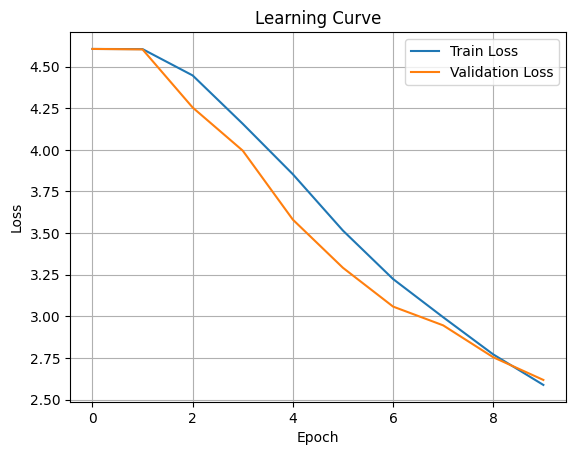

In [23]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label = "Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Learning Curve")
plt.legend()
plt.grid()
plt.show()

## Learning Rate

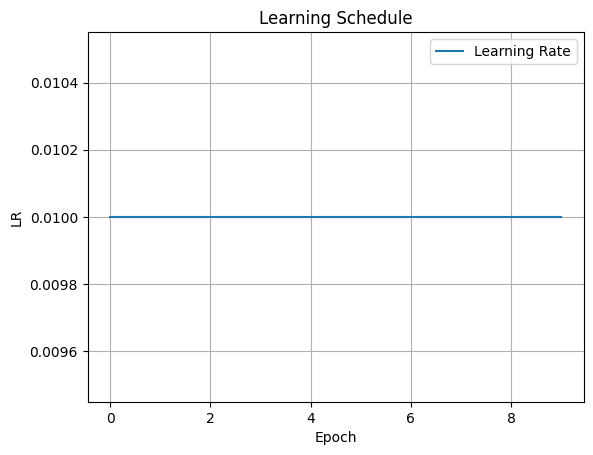

In [24]:
plt.figure()
plt.plot(lrs, label="Learning Rate")
plt.xlabel("Epoch")
plt.ylabel("LR")
plt.title("Learning Schedule")
plt.legend()
plt.grid()
plt.show()

# Saving Model

In [25]:
torch.save(
    model.module.state_dict() if hasattr(model, "module") else model.state_dict(),
    "/kaggle/working/alexnet.pth"
)
print("Model Saved")

Model Saved


# Publishing Model

In [26]:
import json

with open("/kaggle/working/classes.json", "w") as f:
    json.dump(dataset.classes, f)